# Optional workflow: Embedding × Ranker comparison

English | [简体中文](01_retrieval_comparison.zh-CN.ipynb)

## Goal

Fine-tune a single-logit CrossEncoder and separate retrieval/reranking contributions.
Defaults train random tiny BERT embedding/ranker models on the same synthetic
corpus/query/qrels. **Metrics verify mechanics, not domain effectiveness.**

## Setup

From the repository: `python -m pip install -e '.[embedding,ranker,notebooks]'`.
On Colab, place the repository at `/content/advai-notebooks`, install with
`%pip install -e '/content/advai-notebooks[embedding,ranker,notebooks]'` and set `ROOT`.

In [1]:
from pathlib import Path
import sys
import importlib.metadata

# Colab: set ROOT = Path("/content/advai-notebooks") after placing the repo there.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError("Set ROOT to the repository directory before continuing")
sys.path.insert(0, str(ROOT / "src"))
for name in ["torch", "transformers", "sentence-transformers"]:
    print(name, importlib.metadata.version(name))
print("Repository:", ROOT)
from huggingface_hub.utils import disable_progress_bars
from transformers.utils.logging import disable_progress_bar
disable_progress_bars()
disable_progress_bar()


torch 2.14.0
transformers 5.18.0
sentence-transformers 5.7.0
Repository: /Users/xuyi/Documents/workspace/advai-notebooks


## Step 1 — Independent configs, common benchmark

Each model reads its own training config/prepared data and trains independently.
The workflow then loads exports for combined retrieval evaluation; composition
is not a dependency of either trainer.

In [2]:
import tempfile
from advai_notebooks.embedding.config import load_config as load_embedding_config
from advai_notebooks.ranker.config import load_config as load_ranker_config
from advai_notebooks.common.retrieval_data import load_data
from advai_notebooks.embedding.pipeline import run as run_embedding
from advai_notebooks.ranker.pipeline import run as run_ranker

parent = ROOT / "outputs/retrieval"
parent.mkdir(parents=True, exist_ok=True)
EXPERIMENT = Path(tempfile.mkdtemp(prefix="notebook-", dir=parent))
embedding_cfg = load_embedding_config(ROOT / "configs/embedding/smoke.yaml", root=ROOT)
embedding_cfg.output_dir = str(EXPERIMENT / "embedding")
ranker_cfg = load_ranker_config(ROOT / "configs/ranker/smoke.yaml", root=ROOT)
ranker_cfg.output_dir = str(EXPERIMENT / "ranker")
print(load_data(ranker_cfg).summary())
print("Experiment:", EXPERIMENT)

{'documents': 12, 'queries': 18, 'judgments': 216, 'queries_by_split': {'train': 12, 'validation': 3, 'test': 3}, 'fingerprint': 'f96589e88e79ce684f3c8733ae1a3c98a8f028459f6e82e3477efeb2867b2a19', 'document_group_isolation': True}
Experiment: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/retrieval/notebook-gy4ihvzz


## Step 2 — Train Embedding independently

Candidates come only from model retrieval; ground-truth positives are not inserted.
Composition retrieves separately for each embedding and lets both rankers reuse
that candidate set. Ranker training itself reads saved external candidates.

In [3]:
embedding_report = run_embedding(embedding_cfg)
print("Independent embedding export:", embedding_report["export"])

embedding: epoch 1, loss=0.0754, validation mrr@3=1.0000


embedding: epoch 2, loss=0.0000, validation mrr@3=1.0000


Independent embedding export: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/retrieval/notebook-gy4ihvzz/embedding/export


## Step 3 — Train Ranker, select on validation and evaluate test

Positive labels come from qrels with relevance > 0; negatives come from independently
prepared samples. BCEWithLogitsLoss treats positives as binary, while evaluation
nDCG retains grades. Epoch zero participates in selection. Ranker scores are
uncalibrated ranking logits.

In [4]:
ranker_report = run_ranker(ranker_cfg)
print("Selected epoch:", ranker_report["training"]["best_epoch"])
metric = ranker_cfg.evaluation.selection_metric
print("Baseline", metric, ranker_report["baseline_test"]["metrics"][metric])
print("Selected", metric, ranker_report["finetuned_test"]["metrics"][metric])

ranker: epoch 1, loss=0.6940, validation mrr@3=0.0000


ranker: epoch 2, loss=0.6933, validation mrr@3=0.0000


Selected epoch: 0
Baseline mrr@3 0.0
Selected mrr@3 0.0


## Checks — Fixed candidates and six comparisons

Each embedding retrieves independently. For each candidate set, evaluate baseline
and selected rankers, plus embedding-only retrieval: six rows total. Missing
positives remain missing and still count in Recall's denominator.

In [5]:
import json
from IPython.display import display, HTML
from advai_notebooks.workflows.retrieval import compare
from advai_notebooks.workflows.config import load_config as load_workflow_config
workflow_cfg = load_workflow_config(ROOT / "configs/workflows/smoke.yaml")

ranker_dir = Path(ranker_cfg.output_dir)
candidates = json.loads((ranker_dir / "candidates.json").read_text())["splits"]["test"]
rankings = json.loads((ranker_dir / "test_rankings.json").read_text())
for qid, rows in candidates.items():
    ids = {r["doc_id"] for r in rows}
    assert ids == {r["doc_id"] for r in rankings["baseline"][qid]}
    assert ids == {r["doc_id"] for r in rankings["finetuned"][qid]}
comparison = compare(workflow_cfg, embedding_cfg.output_dir, ranker_cfg.output_dir,
                     EXPERIMENT / "comparison.json")
K = 3 if 3 in ranker_cfg.evaluation.cutoffs else (10 if 10 in ranker_cfg.evaluation.cutoffs else ranker_cfg.evaluation.cutoffs[0])
columns = ["embedding", "ranker", f"recall@{K}", f"mrr@{K}", f"ndcg@{K}"]
html = "<table><tr>" + "".join(f"<th>{k}</th>" for k in columns) + "</tr>"
for row in comparison["rows"]:
    html += "<tr>" + "".join(f"<td>{row[k]:.4f}</td>" if isinstance(row[k], float)
                            else f"<td>{row[k]}</td>" for k in columns) + "</tr>"
display(HTML(html + "</table>"))
print("Fixed candidates verified; six-way comparison saved.")

embedding,ranker,recall@3,mrr@3,ndcg@3
baseline,none,1.0000,1.0000,1.0000
baseline,baseline,0.0000,0.0000,0.0000
baseline,finetuned,0.0000,0.0000,0.0000
finetuned,none,1.0000,1.0000,1.0000
finetuned,baseline,0.0000,0.0000,0.0000
finetuned,finetuned,0.0000,0.0000,0.0000


Fixed candidates verified; six-way comparison saved.


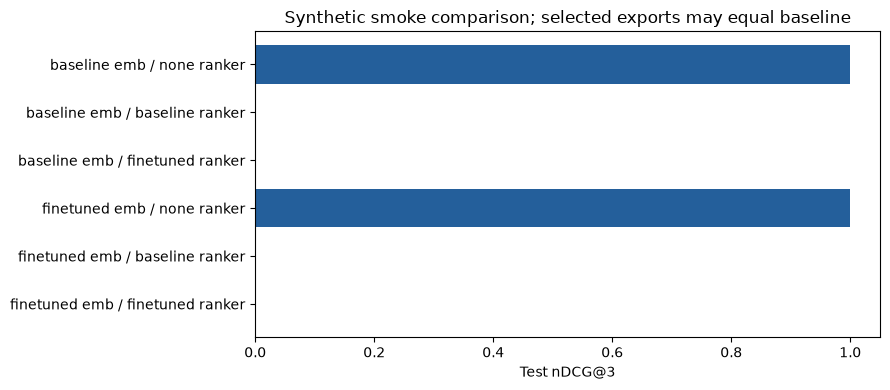

In [6]:
import matplotlib.pyplot as plt
rows = comparison["rows"]
labels = [f"{r['embedding']} emb / {r['ranker']} ranker" for r in rows]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(labels, [r[f"ndcg@{K}"] for r in rows], color=["#245f9b", "#75a4cf", "#37a888"] * 2)
ax.set(xlabel=f"Test nDCG@{K}", xlim=(0, 1.05),
       title="Synthetic smoke comparison; selected exports may equal baseline")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(EXPERIMENT / "comparison.png", dpi=130)
plt.show()

## Step 4 — Reload and verify the native SDK

The wrapper applies query/document prefixes once. Native SDK callers prepare
prefixes from export metadata, then use Identity activation for raw logits.

In [7]:
import numpy as np
import torch
from sentence_transformers import CrossEncoder
from advai_notebooks.ranker.model import RankerModel

model = RankerModel.load(ranker_report["export"], device="cpu")
sdk = CrossEncoder(ranker_report["export"], device="cpu")
pairs = [("reset password", "account login password reset"),
         ("reset password", "payment invoice card refund")]
model.check_lengths(pairs)
scores = model.score(pairs)
expected = sdk.predict(model.prepare(pairs), activation_fn=torch.nn.Identity(), show_progress_bar=False).reshape(-1)
np.testing.assert_allclose(scores, expected, atol=1e-6)
print("Reload and SDK agreement passed.")
for pair, score in sorted(zip(pairs, scores), key=lambda p: -p[1]):
    print(f"{score:.5f}", pair)
print("Report:", ranker_dir / "report.json")

Reload and SDK agreement passed.
0.01315 ('reset password', 'account login password reset')
0.01310 ('reset password', 'payment invoice card refund')
Report: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/retrieval/notebook-gy4ihvzz/ranker/report.json


## Next Steps

- Use domain data with independent query/source groups. Unjudged documents are not automatically valid negatives.
- Adapt `configs/ranker/bge.yaml` for a single-logit classifier, prepared samples and candidate paths.
- Compare rankers on fixed candidates and inspect retrieval Recall ceilings. Measure real-query latency, throughput and GPU memory.
- Extend pairwise/listwise objectives, compression or calibration as needed.

Single-device full training has native inference exports and completed-epoch
optimizer/scaler/RNG recovery with unchanged config/data/source. Inference exports
alone cannot resume. Validate real models/CUDA/MPS quality and resource use separately.